# 3.3 EDA — Riesgo de prórroga en contratos públicos (SECOP II)

**Base v0** (22-oct-2026): 167.997 contratos firmados entre 2019 y 2025, ~24.000 por año. La muestra **no es proporcional por año**: las tasas agrupadas describen la muestra, no la población. Fuente: SECOP II, datos.gov.co (`jbjy-vk9h`, `p6dx-8zbt`), licencia CC BY-SA 4.0.

**Etiqueta v0:** `y = y_dias = dias_adicionados > 0`. La F1 mostró que subestima los positivos: la etiqueta definitiva es "ampliación del plazo" (tasa ~24 %). Todo resultado que dependa de `y` se marca **[PROVISIONAL v0]** y no se interpreta como conclusión. La base v1 llega el domingo en la noche.

**Alcance de hoy:** §2 calidad, §3 distribuciones/deriva/correlación, §4 duración y madurez, §7.1 privacidad del proveedor y §9 decisiones. §4.3, §5, §6, §7.2 y §8 se completan con v1.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import eda
from src import features as F
from src.base import validar_esquema

eda.config_graficas()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

BASE = RAIZ / "data" / "processed" / "base_contratos.parquet"
base, meta = eda.cargar_base(BASE)
validar_esquema(base)
X = F.construir_features(base)
PREFIJO = eda.prefijo_provisional(meta)

print("base:", base.shape, "| features:", X.shape)
print("version:", meta["version"], "| corte:", meta["fecha_de_corte"])
print("anios:", sorted(base["anio_firma"].unique().tolist()))
print("entidades:", base["nit_entidad"].nunique(), "| maduros:", round(100 * base["eval_madura"].mean(), 1), "%")

base: (167997, 47) | features: (167997, 39)
version: v0 | corte: 2026-10-14
anios: [2019, 2020, 2021, 2022, 2023, 2024, 2025]
entidades: 2568 | maduros: 99.2 %


## 1. Carga y mapa de hipótesis

La base cumple el esquema 2a y `construir_features` devuelve las 39 features. El EDA separa lo que no depende de la etiqueta (calidad, distribución, deriva, duración, privacidad) de lo que sí (H1–H7 y etiqueta).

| Hipótesis | Señal al firmar | Feature(s) | Sección |
|---|---|---|---|
| H1. Procesos apresurados | Días entre publicación y firma | `dias_publicacion_a_firma` | 6.1 |
| H2. Poca competencia | Respuestas, oferentes, invitados | `p_respuestas_al_procedimiento`, `p_conteo_de_respuestas_a_ofertas`, `p_proveedores_invitados` | 6.2 |
| H3. Modalidad | Directa frente a competitivas | `modalidad_de_contratacion`, `justificacion_modalidad_de` | 6.3 |
| H4. Anualidad | Firma en el último trimestre | `mes_firma`, `firma_ultimo_trimestre`, `fin_planeado_cruza_anio` | 6.4 |
| H5. Plazos subestimados | Duración planeada | `p_dur_dias`, `p_unidad_de_duracion` | 6.5 |
| H6. Hábitos de la entidad | Tasa histórica de la entidad | `nit_entidad` (TargetEncoder) | 6.6 |
| H7. Tipo de objeto | UNSPSC y tipo de contrato | `unspsc_segmento`, `unspsc_familia`, `tipo_de_contrato`, `len_objeto` | 6.7 |

`y` no se usa en §2–§4; solo en §4.3, §5, §6 y §7.2, que quedan marcadas.

## 2. Calidad de datos

No depende de la etiqueta: se puede cerrar con v0. Se re-ejecuta con v1 para refrescar cifras.

### 2.1 Faltantes

**Qué se observa.** Los faltantes son bajos y vienen en bloques: 215 contratos (0,13 %) no tienen fila de Procesos (todas las `p_*` faltan), `fecha_de_inicio_del_contrato` falta en 1.732 (1,03 %), la duración planeada en 436 (0,26 %) y `unspsc_familia`/`unspsc_segmento` en 1.375 (0,82 %), todos con código `UNSPECIFIED`. `y_modif` falta al 100 % porque la v0 no trae Modificaciones; es esperado.

**Decisión.** Imputar dentro del `Pipeline`, con la mediana/moda aprendida solo en train, y usar indicadores de bloque (`sin_proceso`, `sin_inicio`, `sin_duracion`). No borrar filas: los faltantes son pocos y borrarlas sesgaría la muestra.

Columnas de la base con faltantes:


,columna,tipo,n,faltantes,pct_faltantes,n_unicos
0,y_modif,Int8,167997,167997,100.00,0
1,fecha_de_inicio_del_contrato,datetime64[us],167997,1732,1.03,2829
2,eval_dur_planeada_dias,float32,167997,436,0.26,732
3,eval_fin_planeado,datetime64[us],167997,436,0.26,3546
4,p_fecha_de_publicacion_del,datetime64[us],167997,229,0.14,2803
5,p_conteo_de_respuestas_a_ofertas,float64,167997,215,0.13,42
6,p_duracion,float64,167997,215,0.13,666
7,p_numero_de_lotes,float64,167997,215,0.13,133
8,p_precio_base,float64,167997,215,0.13,73756
9,p_proveedores_con_invitacion,float64,167997,215,0.13,153


Features con faltantes:


,columna,tipo,n,faltantes,pct_faltantes,n_unicos
0,dias_firma_a_inicio,float64,167997,1732,1.03,602
1,unspsc_familia,object,167997,1375,0.82,373
2,unspsc_segmento,object,167997,1375,0.82,56
3,fin_planeado_cruza_anio,float64,167997,436,0.26,2
4,p_dur_dias,float64,167997,436,0.26,732
5,dias_publicacion_a_firma,float64,167997,229,0.14,616
6,log_precio_base,float64,167997,215,0.13,73752
7,p_conteo_de_respuestas_a_ofertas,float64,167997,215,0.13,42
8,p_numero_de_lotes,float64,167997,215,0.13,133
9,p_proveedores_con_invitacion,float64,167997,215,0.13,153


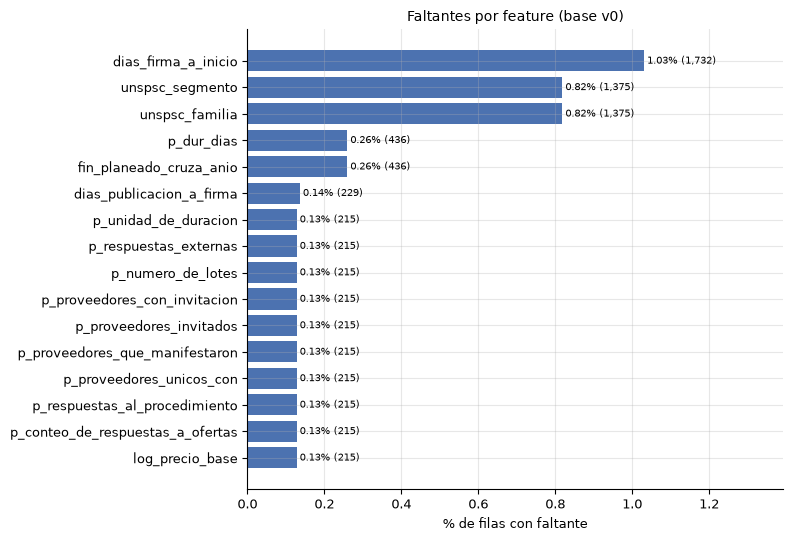

In [2]:
cols_base = [c for c in base.columns if c not in ["id_contrato", "proceso_de_compra"]]
faltantes_base = eda.resumen_faltantes(base, cols_base)
faltantes_x = eda.resumen_faltantes(X, F.FEATURES)

print("Columnas de la base con faltantes:")
display(faltantes_base[faltantes_base["faltantes"] > 0])
print("Features con faltantes:")
display(faltantes_x[faltantes_x["faltantes"] > 0])
eda.graficar_faltantes(faltantes_x, titulo="Faltantes por feature (base v0)")
plt.show()

### 2.2 Valores imposibles

**Qué se observa.** No hay `id_contrato` duplicados, fechas basura, PII ni columnas de fuga. Los problemas están en duración y montos: 8.694 contratos (5,18 %) tienen duración planeada ≤ 0, 66 (0,04 %) pasan de 3.650 días y el máximo es 83,4 millones de días; 26 precios base son negativos, 1.740 son cero y el máximo es 3,4 billones. Además, 2.680 contratos (1,6 %) tienen fin planeado anterior a la firma: en todos el inicio es anterior a la firma y la duración no alcanza a cubrir ese retroceso (518 tienen duración ≤ 0).

**Decisión.** Tratar duración ≤ 0 como faltante y recortar a [1, 3.650] días; no eliminar contratos. `construir_features` ya recorta `dias_firma_a_inicio` y `dias_publicacion_a_firma`, pero no `p_dur_dias`. Los precios negativos quedan en 0 después de `clip(lower=0)` en `log_precio_base`, así que no se pueden separar de los ceros reales: el Pipeline crea `precio_no_positivo = log_precio_base == 0` y documenta la limitación.

In [3]:
imposibles = eda.revisar_valores_imposibles(base)
display(imposibles[imposibles["n"] > 0].reset_index(drop=True))
print("Los chequeos que no aparecen dieron 0.")

,chequeo,n,pct,detalle
0,fecha_de_inicio nula,1732,1.03,
1,inicio mas de 365 dias antes de la firma,369,0.22,
2,inicio mas de 365 dias despues de la firma,57,0.03,
3,p_fecha_de_publicacion nula,229,0.14,
4,p_duracion nula,215,0.13,
5,p_duracion <= 0,8695,5.18,
6,duracion planeada nula,436,0.26,
7,duracion planeada <= 0,8694,5.18,
8,duracion planeada > 3650 dias,66,0.04,
9,p_precio_base nulo,215,0.13,


Los chequeos que no aparecen dieron 0.


### 2.3 Atípicos

**Qué se observa.** Las colas largas están en duración, precio, pago adelantado y competencia. La duración planeada (`eval_dur_planeada_dias`) tiene 5,19 % en cero y 1,44 % fuera de 1,5 IQR, con máximo de 83,4 millones de días; `p_duracion` tiene 7,81 % fuera de 1,5 IQR; `p_precio_base` tiene 14,6 % fuera de 1,5 IQR y máximo de 3,4 billones; `p_proveedores_invitados` llega a 7.388 y `p_respuestas_al_procedimiento` a 254. `len_objeto` está truncado en 500 caracteres.

**Decisión.** No eliminar outliers: son pocos y pueden ser señal. Para kNN/SVM, `log1p` + `RobustScaler`; para HGB, dejar los valores crudos y usar el recorte suave de §2.2. Recortar `p_proveedores_invitados` en el percentil 99,9 solo para modelos de distancia.

,columna,n,n_cero,pct_cero,n_neg,min,p1,p50,p99,max,n_iqr_alto,pct_iqr_alto
0,p_respuestas_al_procedimiento,167782,133046,79.30,0,0.00,0.00,0.00,17.00,254.00,34736,20.70
1,p_precio_base,167782,1740,1.04,26,"-2,386,658,364.00",0.00,"19,500,000.00","4,857,648,927.22","3,406,725,000,000.00",24514,14.61
2,p_numero_de_lotes,167782,152769,91.05,0,0.00,0.00,0.00,30.00,244.00,15013,8.95
3,p_duracion,167782,8695,5.18,0,0.00,0.00,15.00,352.00,"83,400,000.00",13100,7.81
4,p_proveedores_invitados,167782,161729,96.39,0,0.00,0.00,0.00,11.00,"7,388.00",6053,3.61
5,eval_dur_planeada_dias,167561,8694,5.19,0,0.00,0.00,120.00,600.00,"83,400,000.00",2405,1.44
6,valor_de_pago_adelantado,167997,167690,99.82,0,0.00,0.00,0.00,0.00,"38,500,000,000.00",307,0.18
7,len_objeto,167997,1,0.00,0,0.00,27.00,227.00,500.00,500.00,0,0.00


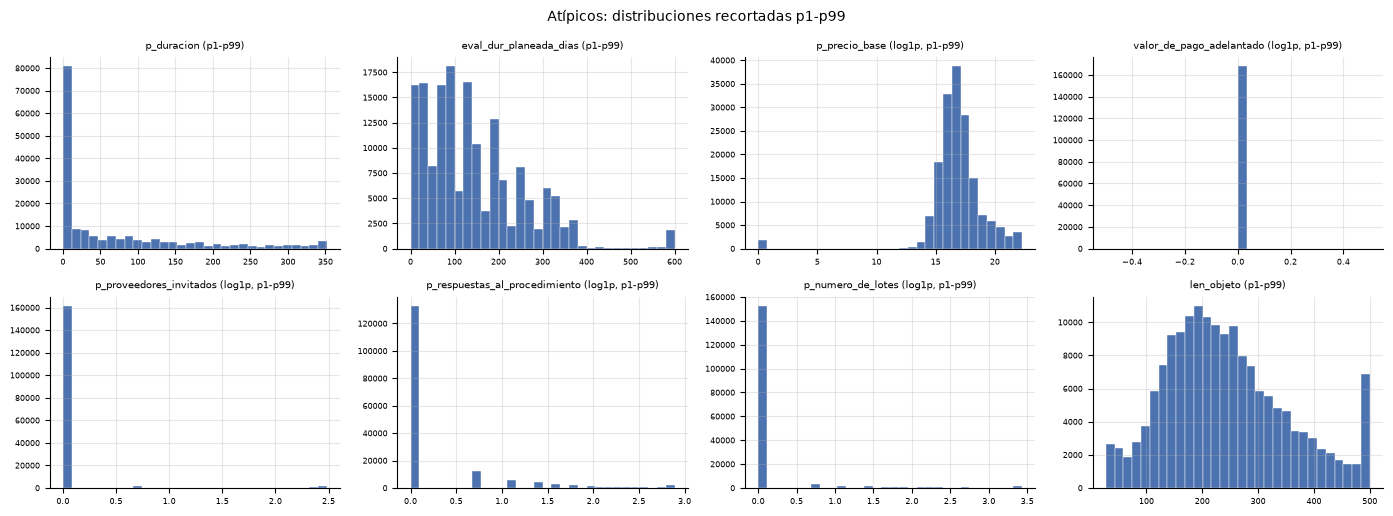

In [4]:
base_atipicos = base.assign(len_objeto=X["len_objeto"])
cols_atipicos = ["p_duracion", "eval_dur_planeada_dias", "p_precio_base", "valor_de_pago_adelantado",
                 "p_proveedores_invitados", "p_respuestas_al_procedimiento", "p_numero_de_lotes", "len_objeto"]
atipicos = eda.resumen_atipicos(base_atipicos, cols_atipicos)
display(atipicos.round(3))
eda.graficar_histogramas(
    base_atipicos, cols_atipicos, ncols=4,
    escala_log=("p_precio_base", "valor_de_pago_adelantado", "p_proveedores_invitados",
                "p_respuestas_al_procedimiento", "p_numero_de_lotes"),
    titulo="Atípicos: distribuciones recortadas p1-p99",
)
plt.show()

### 2.4 Cardinalidad de las categóricas

**Qué se observa.** `nit_entidad` (2.568), `ciudad` (664), `unspsc_familia` (373) y `unspsc_segmento` (56) concentran la cardinalidad alta. En el resto, las categorías raras (<1 %) son pocas: `justificacion` 31 categorías/4,1 % de filas, `departamento` 14/6,2 %, `sector` 7/3,0 %, `tipo_de_contrato` 17/2,4 %, `modalidad` 7/1,8 %, `tipodocproveedor` 7/0,9 %. `ciudad` tiene 648 categorías raras y 24,8 % de las filas; `nit_entidad` tiene 2.559 categorías con <1 % y 77,1 % de las filas, pero es la señal de H6 y va con TargetEncoder, no con one-hot.

**Decisión.** Para one-hot/kNN/SVM: agrupar categorías <1 % en `OTROS` y mantener `No Definido` como categoría o faltante explícito. Para HGB: categorías nativas con tope (200) o códigos ordinales; `nit_entidad` solo con `TargetEncoder` dentro del `Pipeline`.

,columna,n_unicos,nulos,top,top_pct,n_categorias_lt_1pct,pct_filas_lt_1pct
0,nit_entidad,2568,0,899999034,4.56,2559,77.13
1,ciudad,664,0,No Definido,23.49,648,24.84
2,unspsc_familia,373,1375,8011,53.91,360,22.10
3,unspsc_segmento,56,1375,80,62.32,48,15.35
4,justificacion_modalidad_de,39,0,Servicios profesionales y apoyo a la gestión,61.41,31,4.07
5,departamento,34,0,Distrito Capital de Bogotá,37.52,14,6.22
6,sector,25,0,Servicio Público,22.47,7,2.95
7,tipo_de_contrato,23,0,Prestación de servicios,77.64,17,2.43
8,modalidad_de_contratacion,14,0,Contratación directa,65.04,7,1.79
9,tipodocproveedor,9,0,Cédula de Ciudadanía,74.64,7,0.89


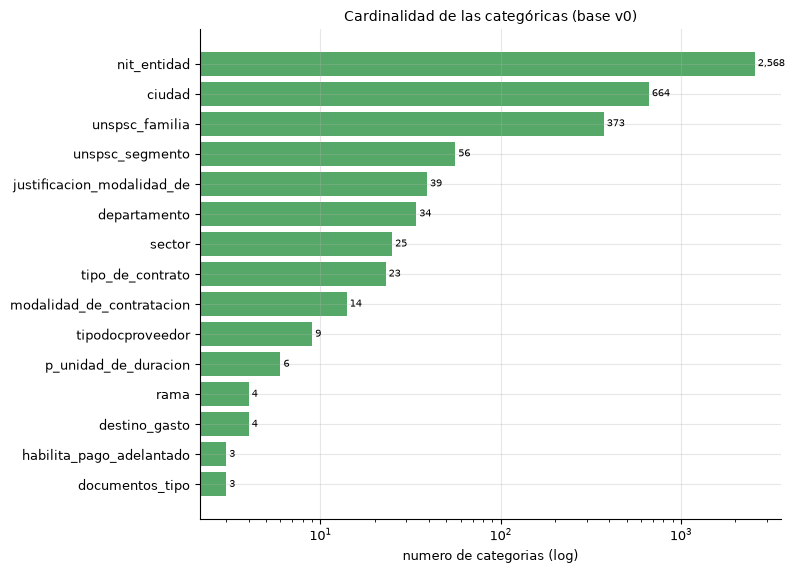

In [5]:
card = eda.cardinalidad_categoricas(X, F.FEATURES_CAT)
display(card.round(2))
eda.graficar_cardinalidad(card, top=15, titulo="Cardinalidad de las categóricas (base v0)")
plt.show()

## 3. Distribución de features y deriva por año

No depende de la etiqueta. Se revisan las 18 numéricas y las 21 categóricas, y se comparan 2019–2025 para detectar deriva.

### 3.1 Distribución de las numéricas

**Qué se observa.** La mayoría son cero-infladas: `log_pago_adelantado` 99,8 % en cero, `p_proveedores_invitados` 96,4 %, `p_numero_de_lotes` 91,1 %, `p_respuestas_al_procedimiento` 79,3 %. `p_dur_dias` tiene mediana 120 días y p95 333; `log_precio_base` mediana 16,79 (unos 19,5 millones) y p99 22,30 (unos 4,9 mil millones). El calendario está repartido; `firma_ultimo_trimestre` es 25 %.

**Decisión.** Para kNN/SVM: usar tal cual `log_precio_base` y `log_pago_adelantado` (ya vienen en `log1p`), aplicar `log1p` a los conteos crudos y `RobustScaler` después; para HGB: valores crudos y flags de cero. No imputar los ceros de competencia: son "sin respuesta", no faltantes.

,columna,n,media,std,min,p1,p5,p50,p95,p99,max,pct_cero
0,log_pago_adelantado,167997,0.03,0.79,0.00,0.00,0.00,0.00,0.00,0.00,24.37,99.82
1,len_objeto,167997,241.86,109.68,0.00,27.00,84.00,227.00,467.00,500.00,500.00,0.00
2,dias_firma_a_inicio,166265,-0.67,31.82,-365.00,-128.00,-7.00,1.00,13.00,40.00,365.00,31.09
3,mes_firma,167997,6.50,3.45,1.00,1.00,1.00,6.00,12.00,12.00,12.00,0.00
4,dia_semana,167997,2.25,1.51,0.00,0.00,0.00,2.00,4.00,6.00,6.00,15.57
5,firma_ultimo_trimestre,167997,0.25,0.43,0.00,0.00,0.00,0.00,1.00,1.00,1.00,75.00
6,fin_planeado_cruza_anio,167561,0.28,0.45,0.00,0.00,0.00,0.00,1.00,1.00,1.00,71.83
7,log_precio_base,167782,16.88,2.42,0.00,0.00,14.69,16.79,20.45,22.30,28.86,1.05
8,p_dur_dias,167561,691.78,"203,978.28",0.00,0.00,0.00,120.00,333.00,600.00,"83,400,000.00",5.19
9,dias_publicacion_a_firma,167768,12.22,42.73,0.00,0.00,0.00,2.00,47.00,167.33,"1,000.00",30.03


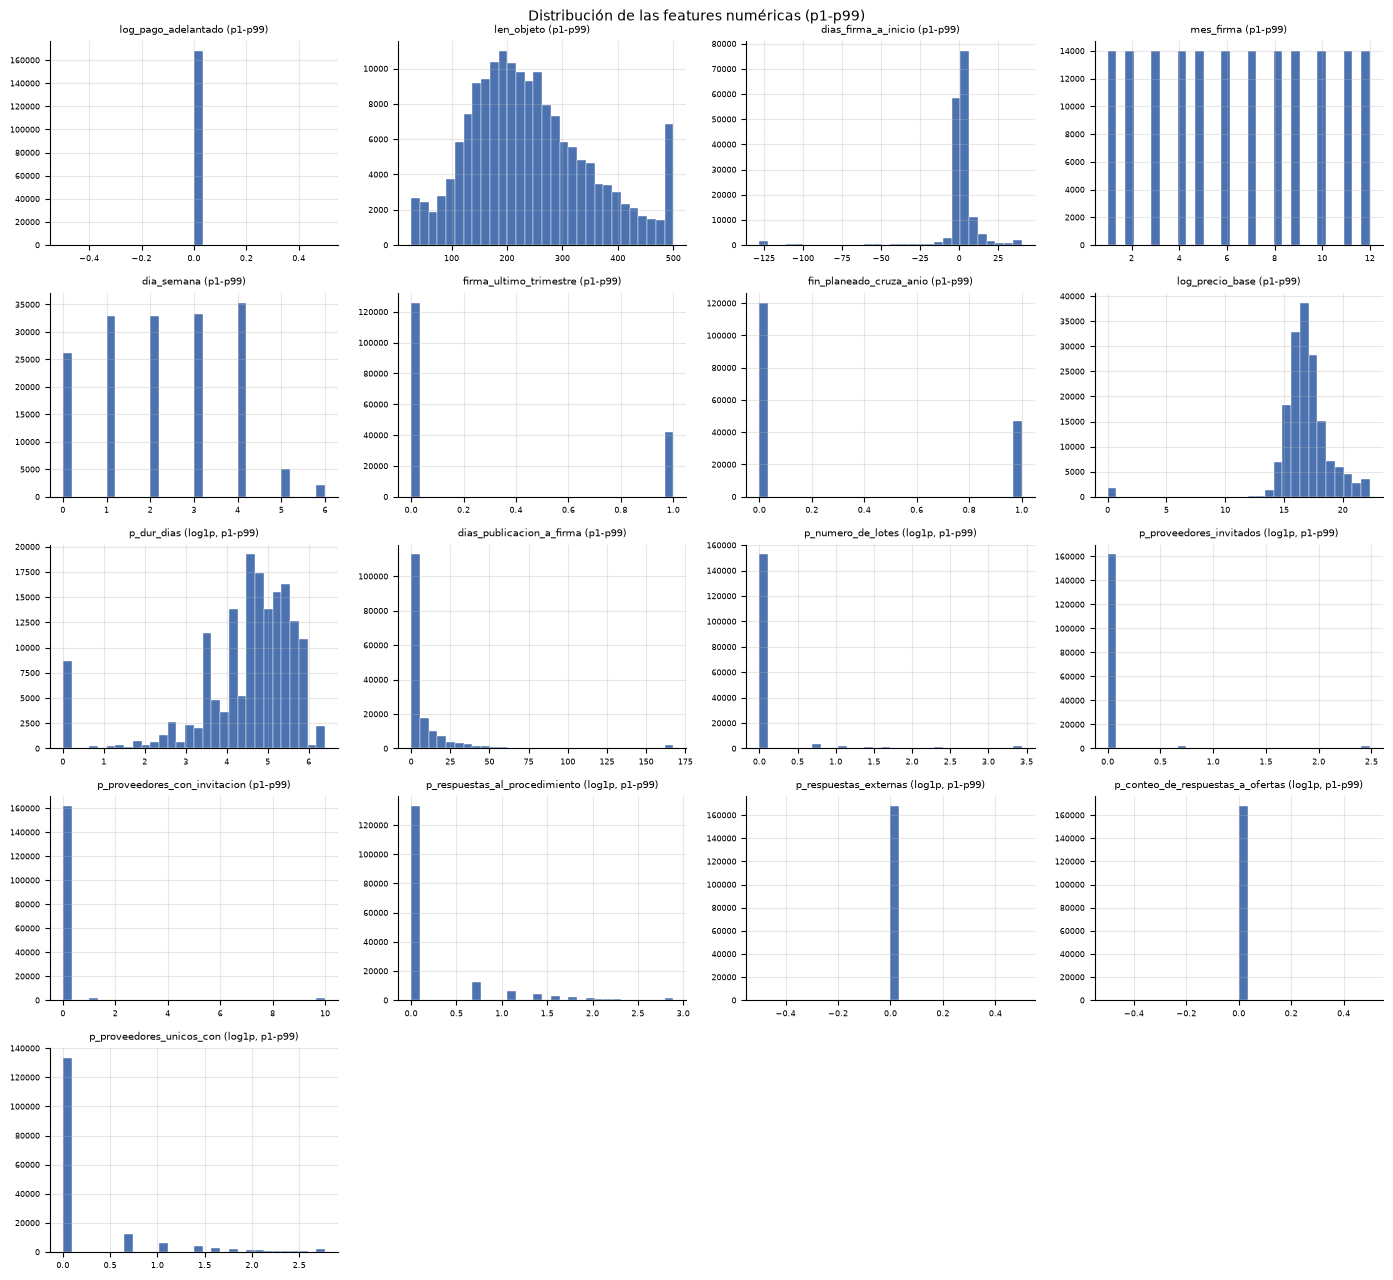

In [6]:
num_plot = [c for c in F.FEATURES_NUM if X[c].nunique() > 1]
display(eda.distribucion_numericas(X, F.FEATURES_NUM).round(2))
eda.graficar_histogramas(
    X, num_plot, ncols=4,
    escala_log=("p_dur_dias", "p_numero_de_lotes", "p_proveedores_invitados",
                "p_respuestas_al_procedimiento", "p_respuestas_externas",
                "p_conteo_de_respuestas_a_ofertas", "p_proveedores_unicos_con"),
    titulo="Distribución de las features numéricas (p1-p99)",
)
plt.show()

### 3.2 Composición de las categóricas

**Qué se observa.** El contrato típico es prestación de servicios (77,6 %), contratación directa (65,0 %), proveedor con cédula (74,6 %), en Bogotá/Valle/Antioquia. `No Definido` aparece en `ciudad` 23,5 %, `departamento` 2,0 %, `destino_gasto` 0,5 % y `tipodocproveedor` 0,4 %. `documentos_tipo` usa "No" y "No definido" como categorías distintas; `destino_gasto` usa "No Definido" y "No aplica".

**Decisión.** Normalizar texto (minúsculas, sin espacios) y unificar "No definido"/"No Definido" en una sola categoría; `No Definido` en `ciudad` se trata como categoría (no como faltante) porque puede informar la calidad del registro. Las categorías raras se agrupan como en §2.4.

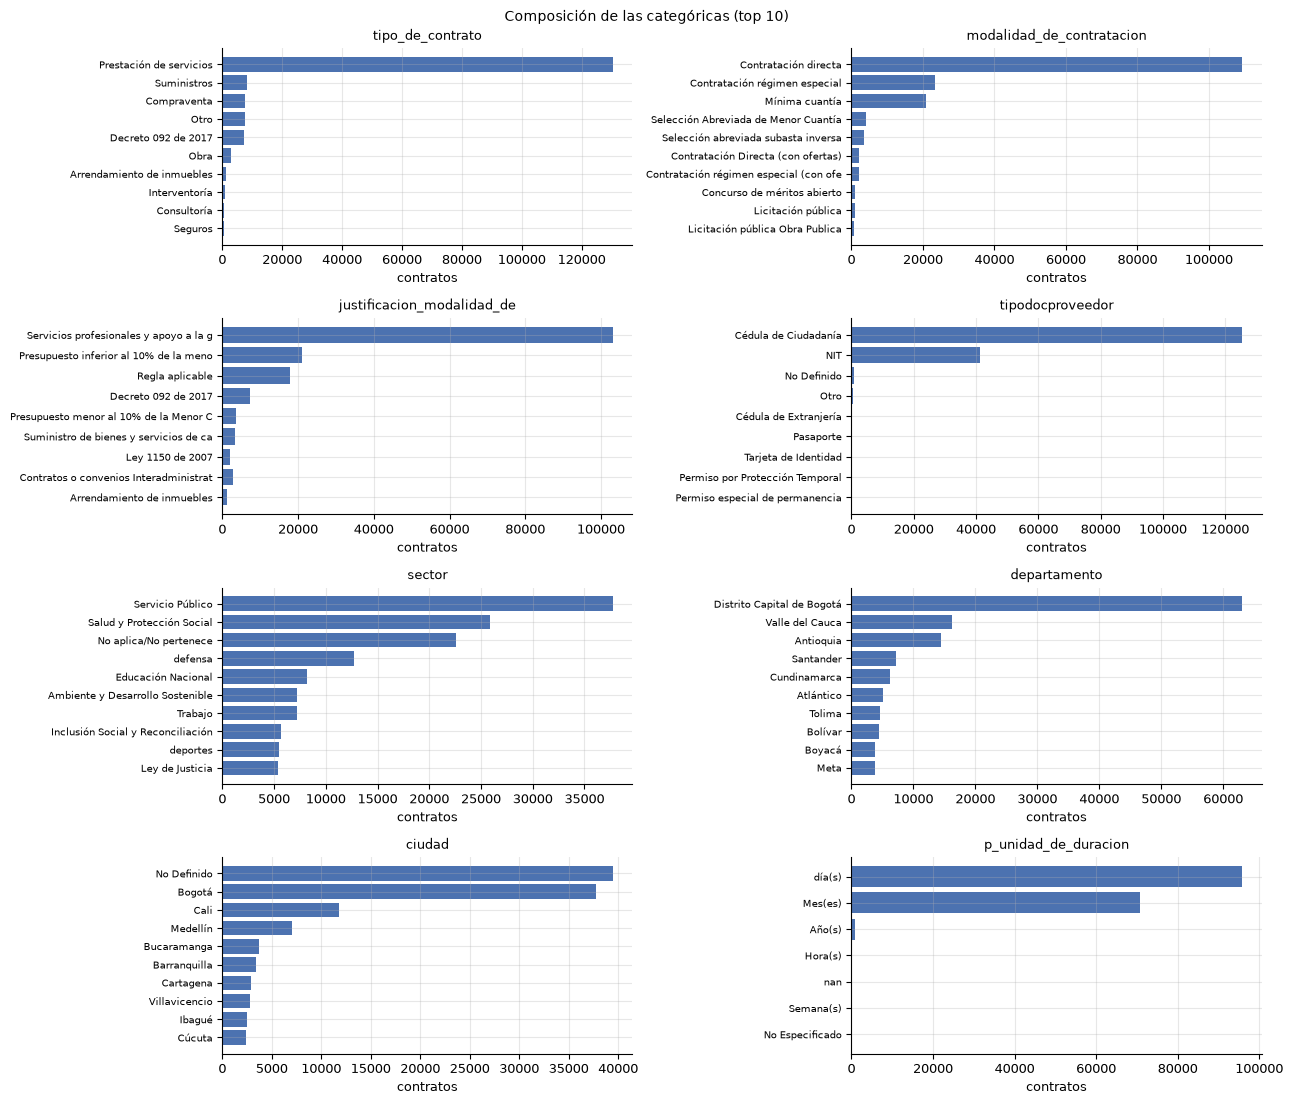

In [7]:
cats_plot = ["tipo_de_contrato", "modalidad_de_contratacion", "justificacion_modalidad_de",
             "tipodocproveedor", "sector", "departamento", "ciudad", "p_unidad_de_duracion"]
eda.graficar_barras_categoricas(X, cats_plot, top=10, ncols=2,
                                titulo="Composición de las categóricas (top 10)")
plt.show()

### 3.3 Deriva numérica por año

**Qué se observa.** 2019 es atípico y 2020–2021 cambian la composición; 2023–2025 son más estables. Las medianas de duración se mueven entre 111 y 125 días; el precio base mediano baja de 17,33 (2019) a 16,64–16,80 (2020–2025); la competencia tiene ceros altos en todos los años (entre 39 % y 99 % según la variable). El cambio más fuerte está en las categóricas (§3.4), no en las numéricas.

**Decisión.** No usar `anio_firma` como feature. Ajustar imputación/escalado solo con train y validar temporalmente. En J3, probar como sensibilidad excluir 2019 del train; el plan fija 2019–2023, así que no se cambia hoy.

,mediana_inicio,mediana_fin,cambio_abs,z_max,cambio_2023_2024
dias_firma_a_inicio,-1.00,1.00,2.00,2.45,0.00
p_respuestas_al_procedimiento,1.00,0.00,-1.00,2.45,0.00
p_proveedores_unicos_con,1.00,0.00,-1.00,2.45,0.00
dias_publicacion_a_firma,18.00,1.00,-17.00,2.45,0.00
log_precio_base,17.33,16.80,-0.53,2.38,0.04
len_objeto,199.00,233.00,34.00,2.10,1.00
mes_firma,6.50,6.50,0.00,1.58,-0.50
p_dur_dias,120.00,120.00,0.00,1.53,-6.00
log_pago_adelantado,0.00,0.00,0.00,0.00,0.00
firma_ultimo_trimestre,0.00,0.00,0.00,0.00,0.00


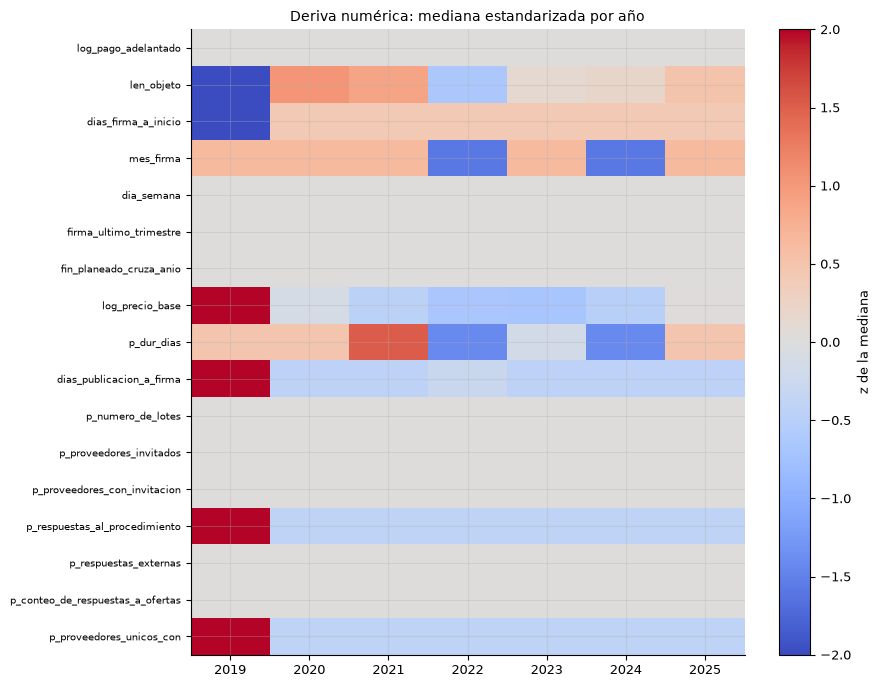

In [8]:
X_anio = X.assign(anio_firma=base["anio_firma"])
medianas, z, cambios = eda.deriva_numericas(X_anio, num_plot)
display(cambios.round(2))
eda.graficar_deriva_numericas(z, titulo="Deriva numérica: mediana estandarizada por año")
plt.show()

### 3.4 Deriva categórica por año

**Qué se observa.** Entre 2019 y 2025: cédula 44,6 %→82,4 %, NIT 53,1 %→17,1 %, contratación directa 24,2 %→72,5 %, prestación de servicios 52,0 %→82,9 %, UNSPSC 80 30,7 %→70,1 %, mínima cuantía 38,3 %→6,0 %. El salto ocurre en 2020–2021 y se estabiliza desde 2023.

**Decisión.** Misma que §3.3: no usar el año como feature; el preprocesamiento se ajusta con train. Reportar la deriva en §3.9 (monitoreo) y no comparar composiciones de 2019 con 2024 sin tenerla en cuenta.

,columna,top_inicio,pct_inicio,top_fin,pct_fin,cambio_max_pp,categoria_cambio
0,modalidad_de_contratacion,Mínima cuantía,38.32,Contratación directa,72.47,48.32,Contratación directa
1,unspsc_segmento,80,30.66,80,70.05,39.39,80
2,tipodocproveedor,NIT,53.15,Cédula de Ciudadanía,82.35,37.74,Cédula de Ciudadanía
3,tipo_de_contrato,Prestación de servicios,51.96,Prestación de servicios,82.95,30.98,Prestación de servicios


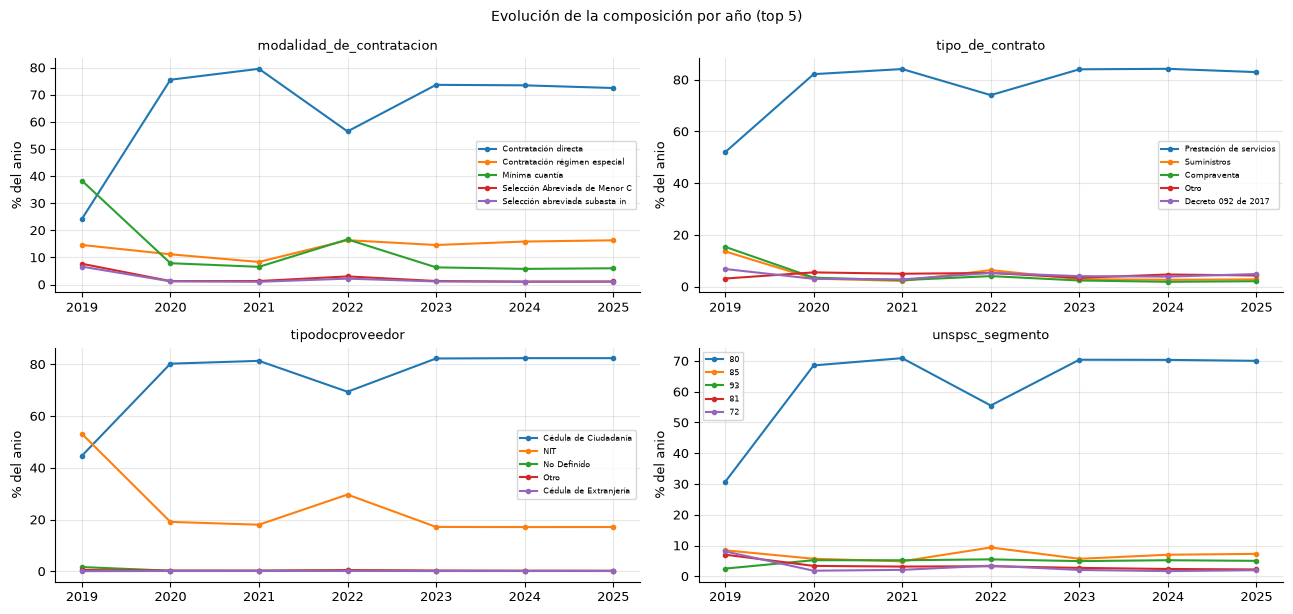

In [9]:
cats_deriva = ["modalidad_de_contratacion", "tipo_de_contrato", "tipodocproveedor", "unspsc_segmento"]
display(eda.resumen_deriva_categoricas(X_anio, cats_deriva).round(2))
eda.graficar_evolucion_categorias(X_anio, cats_deriva, top=5, ncols=2,
                                  titulo="Evolución de la composición por año (top 5)")
plt.show()

### 3.5 Matriz de correlación de las numéricas

**Qué se observa.** Se excluye `p_proveedores_que_manifestaron` porque es constante 0. Con Spearman, hay dos pares casi duplicados: `p_proveedores_invitados` y `p_proveedores_con_invitacion` (r = 0,996; el segundo nunca es mayor y es igual en 99,59 % de las filas) y `p_respuestas_al_procedimiento` y `p_proveedores_unicos_con` (r = 0,995; iguales en 99,04 %). `mes_firma` y `firma_ultimo_trimestre` correlacionan 0,753 porque el flag es una transformación del mes. Con Pearson, `dias_firma_a_inicio` y `dias_publicacion_a_firma` dan −0,743, pero con Spearman solo −0,101: la correlación la producen los valores extremos, no el grueso de los datos. En Pearson, `p_respuestas_al_procedimiento` y `p_proveedores_unicos_con` siguen en 0,971, mientras que `p_proveedores_invitados` y `p_proveedores_con_invitacion` caen a 0,073 porque casi siempre valen 0 y su relación es de orden, no lineal.

**Qué implica para kNN y SVM.** La colinealidad no rompe el modelo, pero duplica el peso de la misma señal en la distancia y en el kernel. Para kNN/SVM: dejar un representante de cada par redundante (`p_proveedores_invitados` y `p_respuestas_al_procedimiento`), y para el calendario quedarse con `firma_ultimo_trimestre` o codificar el mes de forma cíclica. Para HGB, que parte el espacio por variable, la colinealidad importa menos: se pueden mantener las dos y la ablación de J3 decide.

**Decisión.** Para kNN/SVM: eliminar `p_proveedores_que_manifestaron` (constante 0), `p_proveedores_con_invitacion` y `p_proveedores_unicos_con`, y no usar `mes_firma` junto con `firma_ultimo_trimestre`. Para HGB: mantener todas y medir en J3. Evidencia: correlaciones y duplicación de filas.

Spearman |r| >= 0,7:


,feature_1,feature_2,r,abs_r
0,p_proveedores_invitados,p_proveedores_con_invitacion,0.996,0.996
1,p_respuestas_al_procedimiento,p_proveedores_unicos_con,0.995,0.995
2,mes_firma,firma_ultimo_trimestre,0.753,0.753


Pearson |r| >= 0,7:


,feature_1,feature_2,r,abs_r
0,p_respuestas_al_procedimiento,p_proveedores_unicos_con,0.971,0.971
1,mes_firma,firma_ultimo_trimestre,0.753,0.753
2,dias_firma_a_inicio,dias_publicacion_a_firma,-0.743,0.743


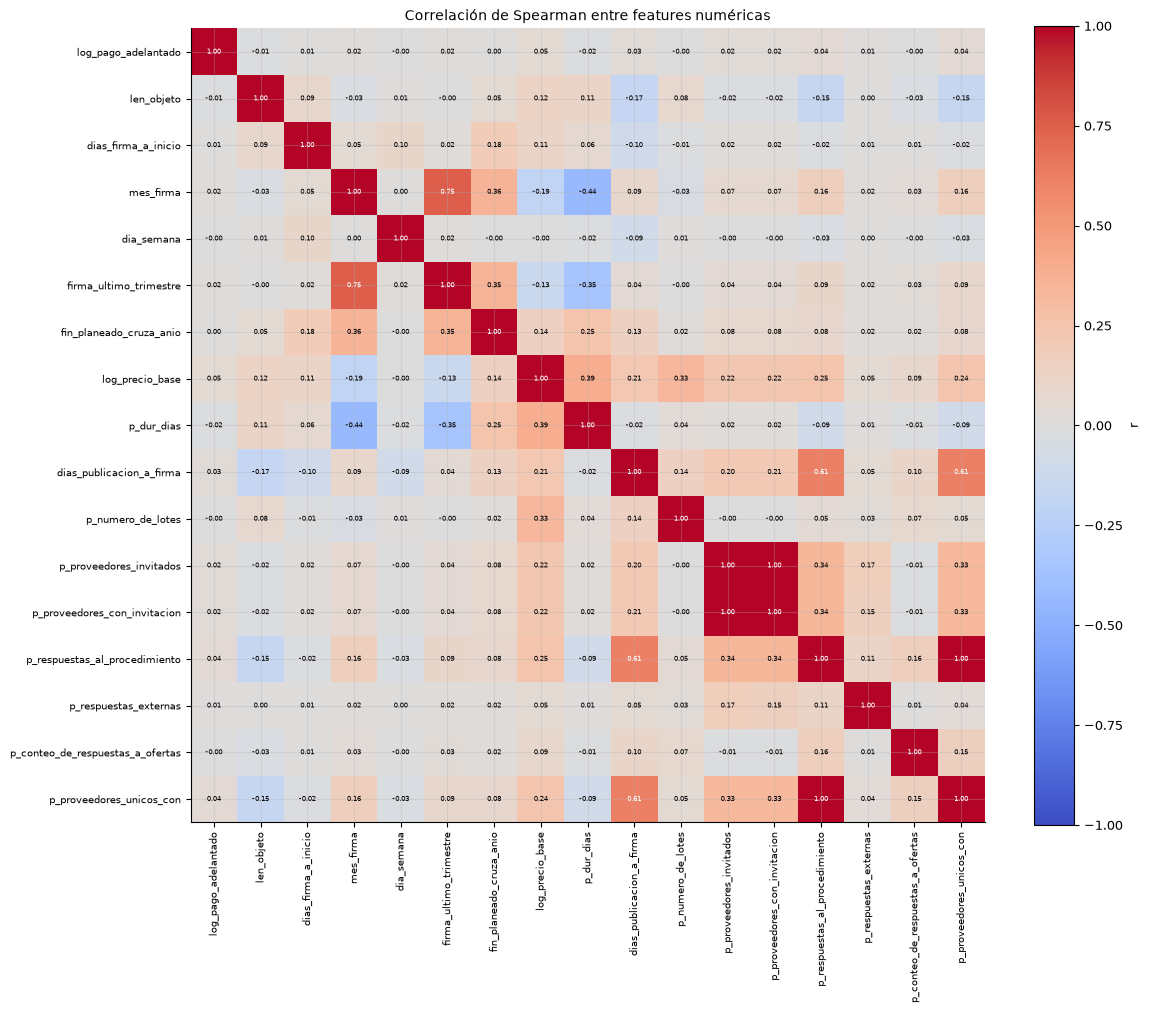

In [10]:
num_corr = [c for c in F.FEATURES_NUM if X[c].nunique() > 1]
corr_s = eda.matriz_correlacion(X, num_corr, metodo="spearman")
pares_s = eda.pares_correlacionados(corr_s, umbral=0.7)
corr_p = X[num_corr].corr(method="pearson")
pares_p = eda.pares_correlacionados(corr_p, umbral=0.7)

print("Spearman |r| >= 0,7:")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pares_s)
print("Pearson |r| >= 0,7:")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pares_p)
eda.graficar_matriz_correlacion(corr_s, titulo="Correlación de Spearman entre features numéricas")
plt.show()

## 4. Duración planeada y madurez (censura)

La madurez es mecánica: `eval_madura = fin planeado + 60 días <= fecha de corte`, con `fin planeado = inicio (o firma) + duración del proceso`. No depende de la etiqueta; la relación entre madurez y `y` se ve en §4.3 con v1.

**Qué se observa.** La duración mediana es 111–125 días; el 5,18 % tiene duración ≤ 0 y el 0,26 % no tiene duración. La fracción madura va de 99,85 % (2019) a 97,37 % (2025); en total 99,2 %. Los 1.360 inmaduros son 436 sin duración y 924 con fin planeado + 60 días después del corte.

**Decisión.** Entrenar y evaluar solo con `eval_madura = True`; imputar `p_dur_dias` para las features, pero no usar `eval_*` como features. Reportar métricas por tramo de duración (≤ 3, 3–6, 6–12, > 12 meses) en la evaluación (requisito 3.7).

,n,dur_mediana,dur_p95,pct_sin_duracion,pct_duracion_le0,pct_duracion_gt3650,pct_madura
anio_firma,,,,,,,
2019,24000,120.00,348.00,0.10,2.96,0.04,99.85
2020,24000,120.00,345.00,0.08,3.71,0.04,99.86
2021,24000,125.00,337.00,0.13,4.93,0.04,99.64
2022,23998,111.00,345.00,0.32,6.31,0.05,99.34
2023,24000,117.00,330.00,0.16,6.68,0.03,99.48
2024,23999,111.00,330.00,0.42,5.97,0.04,98.80
2025,24000,120.00,324.00,0.60,5.65,0.04,97.37


,n,pct,pct_madura
tramo,,,
<=30,21667,12.90,100.00
31-90,43366,25.81,100.00
91-180,48886,29.10,99.99
181-365,42144,25.09,99.31
366-3650,2738,1.63,79.62
>3650,66,0.04,0.00
Sin duracion / <=0,9130,5.43,95.21


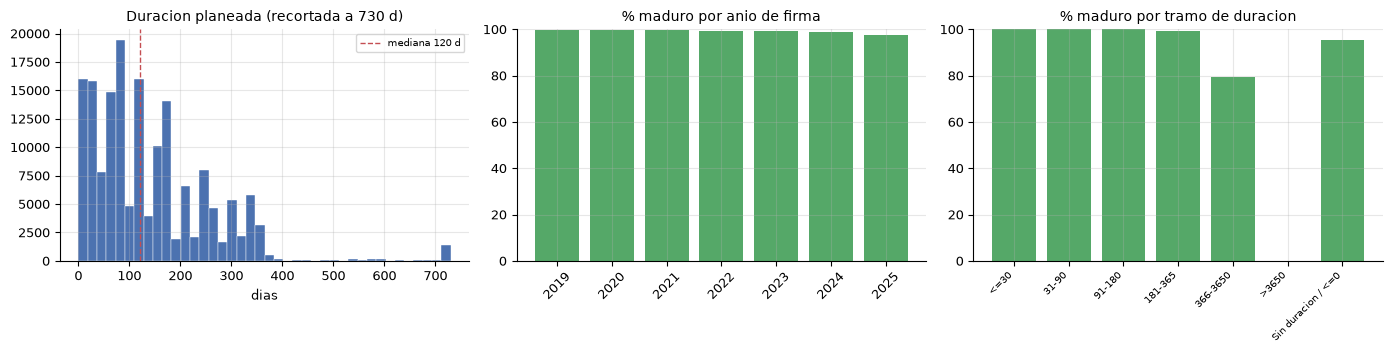

In [11]:
por_anio, por_tramo = eda.resumen_duracion_madurez(base)
display(por_anio)
display(por_tramo)
eda.graficar_duracion_madurez(base, por_anio, por_tramo)
plt.show()

### 4.3 [PROVISIONAL v0] Madurez y etiqueta

Se completa en el paso 3, junto con §5 y §6. Hoy no se interpreta: la etiqueta v0 esconde la mitad de las prórrogas y la relación entre censura y `y` puede cambiar con la v1.

## 7. Privacidad del proveedor

**Qué se observa.** El 74,6 % de los contratos tiene proveedor con cédula de ciudadanía, 24,5 % con NIT, 0,4 % "No Definido" y 0,3 % "Otro". La composición cambia fuerte en 2019 (44,6 % cédula / 53,1 % NIT) y se estabiliza desde 2023 (82,2–82,4 % / 17,1–17,2 %). Es decir, cerca de tres de cada cuatro contratos tienen un proveedor con cédula, un dato personal.

**Decisión.**
- **Decisión:** excluir la identidad y los datos del proveedor (documento, nombre, `codigo_proveedor`, NIT adjudicado); conservar solo `tipodocproveedor`.
- **Alternativas:** historial de prórrogas del proveedor; identificador cifrado (hash); usar solo personas jurídicas (NIT); excluir.
- **Por qué:** la cédula es dato personal (Ley 1581 de 2012); el hash sigue siendo un dato personal seudonimizado y un puntaje por proveedor se convierte en un ranking de personas. El tipo de documento no identifica.
- **Evidencia:** distribución de `tipodocproveedor` y su evolución por año.
- **Costo:** se pierde una posible señal (historial del proveedor) cuyo tamaño no se midió [NO EVALUADO].

,tipo,n,pct,pct_acumulado
0,Cédula de Ciudadanía,125397,74.64,74.64
1,NIT,41107,24.47,99.11
2,No Definido,690,0.41,99.52
3,Otro,537,0.32,99.84
4,Cédula de Extranjería,205,0.12,99.96
5,Pasaporte,22,0.01,99.98
6,Tarjeta de Identidad,18,0.01,99.99
7,Permiso por Protección Temporal,17,0.01,100.00
8,Permiso especial de permanencia,4,0.00,100.00


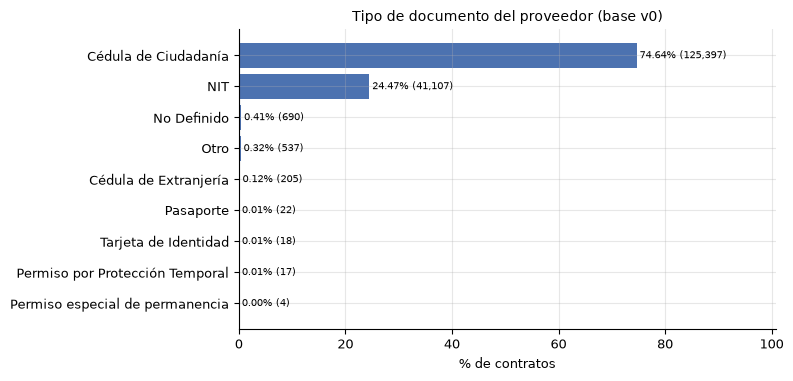

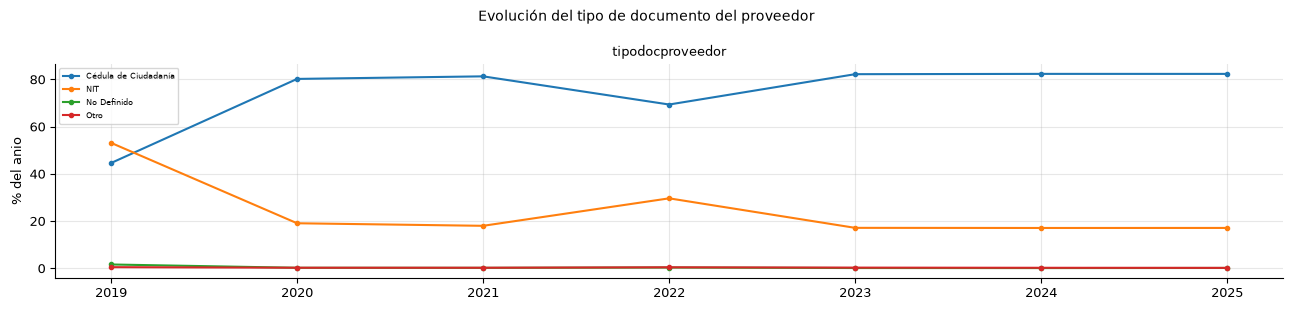

In [12]:
tipo_doc = eda.resumen_tipodocproveedor(base)
display(tipo_doc.round(2))
eda.graficar_tipodocproveedor(tipo_doc, titulo="Tipo de documento del proveedor (base v0)")
plt.show()
eda.graficar_evolucion_categorias(base, ["tipodocproveedor"], top=4, ncols=1,
                                  titulo="Evolución del tipo de documento del proveedor")
plt.show()

## 8. Fuga de información (pendiente v1)

No se puede cerrar hoy: las columnas de fuga (`estado_contrato`, `fecha_de_fin_del_contrato`, `valor_del_contrato`, montos por fuente de recursos) viven en `data/raw/` de la carpeta principal y la F3 las deja el lunes. La evidencia esperada es el contraste con y sin esas columnas: ROC-AUC/PR-AUC cerca de 0,95/0,84 con fuga frente a la referencia limpia. También queda pendiente confrontar `COLUMNAS_FUGA` con `docs/LISTA_FUGA.md` cuando exista.

**Cuando llegue la v1:** unir `data/raw` por `id_contrato`, entrenar el mismo HGB con y sin las columnas de fuga, reportar la diferencia y confirmar que ninguna entra a `FEATURES`.

## 9. Resumen de decisiones

| ID | Decisión | Alternativas | Por qué | Evidencia | Va a |
|---|---|---|---|---|---|
| D2.1 | Imputar en el Pipeline con mediana/moda + indicadores de bloque | Borrar filas; imputar con 0 | Faltantes bajos y en bloque; borrar sesga | 215 sin proceso, 1.732 sin inicio, 436 sin duración, 1.375 sin UNSPSC | J2 |
| D2.2 | Duración ≤0 → faltante y recorte [1, 3.650]; precio negativo → flag (ya queda en 0 en `log_precio_base`) | Dejar crudo; borrar outliers | 5,18 % de duraciones no positivas y colas de 83,4 M | 8.694 ≤0, 66 >3.650, 26 precios negativos | J2 |
| D2.3 | Agrupar raras <1 % en `OTROS`; HGB nativo/tope; `nit_entidad` con TargetEncoder | One-hot completo; dejar texto | Cardinalidad alta y 77 % de filas en entidades con <1 % | 2.568 entidades, 664 ciudades | J2 |
| D2.4 | Eliminar constantes/redundantes | Mantener las 18 numéricas | Duplican la misma señal | 1 constante (`p_proveedores_que_manifestaron`), 99,59 %/99,04 % iguales, r 0,996/0,995 | J2 |
| D3.1 | `log1p` en conteos + `RobustScaler` para kNN/SVM; crudo para HGB | Estandarizar sin log | Zero-inflación y colas largas | 79–99 % ceros en competencia | J2 |
| D3.2 | No usar el año como feature; ajustar solo con train | Usar año; mezclar train/test | Deriva fuerte 2019→2025 | Composición y competencia cambian | J2/J3 |
| D3.3 | Quitar redundantes para kNN/SVM; mantener para HGB | PCA | Colinealidad duplica peso | r 0,996 y 0,995 | J2/J3 |
| D3.4 | Calendario: flag de trimestre + mes cíclico o uno solo para distancia | Mes ordinal | `mes_firma` y el flag correlacionan 0,75 | r = 0,75 | J2 |
| D4.1 | Entrenar/evaluar solo maduros; `eval_*` nunca como feature | Usar todos | 99,2 % maduro; 1.360 inmaduros | Madurez 97,4–99,9 % por año | J2/J3 |
| D7.1 | Excluir identidad del proveedor; conservar solo el tipo de documento | Hash; historial; solo NIT | 74,6 % de los contratos tiene proveedor con cédula | Distribución `tipodocproveedor` | J3/app |

**Pendiente v1:** §4.3 (madurez vs `y`), §5 (`y` vs `y_dias` y tasa por año), §6 (H1–H7 con interpretación), §7.2 (tasa por tipo de documento), §8 (fuga). El detalle para Jose está en `docs/EDA_INSIGHTS_PREPROCESAMIENTO.md`.

In [13]:
print("Secciones cerradas hoy: 2, 3, 4.1-4.2, 7.1 y 9.")
print("Pendientes v1: 4.3, 5, 6, 7.2 y 8.")

Secciones cerradas hoy: 2, 3, 4.1-4.2, 7.1 y 9.
Pendientes v1: 4.3, 5, 6, 7.2 y 8.
